<a href="https://colab.research.google.com/github/francescaarrusm/5685052---DataScience-GenAI-Submissions/blob/main/W5_RF_and_GBDT_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Individual Practice: Random Forest and Gradient Boosting Decision Trees**

In [1]:
from google.colab import files
uploaded = files.upload()

Saving credit_data_final.csv to credit_data_final.csv


In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv('credit_data_final.csv')

y_value = df['class']
y_values = np.ravel(y_value)

x_values = df.drop('class', axis=1)

from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.1, random_state=4567, stratify=y_value)

print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(900, 28)
(100, 28)
(900,)
(100,)


In [18]:
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB
from sklearn.metrics import precision_recall_fscore_support

LogR_algo = LogR()
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF()
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT()
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB()
XGB_model = XGB_algo.fit(X_train, Y_train)

# Make sure names and models are defined
models = [LogR_model, RF_model, GBDT_model, XGB_model]
names = ['Logistic Regression', 'Random Forest', 'GBDT', 'XGBDT']

for i in range(4):
  print(f"Model: {names[i]}")
  print(f"  Training Accuracy: {models[i].score(X_train, Y_train):.4f}")
  print(f"  Testing Accuracy:  {models[i].score(X_test, Y_test):.4f}")

  predict = models[i].predict(X_train)

    # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')

    # Print only the requested metrics
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n") # Print a space between models

Model: Logistic Regression
  Training Accuracy: 0.7389
  Testing Accuracy:  0.6600
Macro Precision: 0.6945378439580046
Macro Recall: 0.6166666666666667
Macro F1-score: 0.6243279199845113


Model: Random Forest
  Training Accuracy: 1.0000
  Testing Accuracy:  0.7500
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


Model: GBDT
  Training Accuracy: 0.8856
  Testing Accuracy:  0.7600
Macro Precision: 0.887785226643705
Macro Recall: 0.8335978835978837
Macro F1-score: 0.854270716903182


Model: XGBDT
  Training Accuracy: 1.0000
  Testing Accuracy:  0.7800
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




In [19]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
import warnings
warnings.filterwarnings("ignore")

# Create a hyperparameter search function for re-usability
def random_search(algo, hyperparameters, X_train, Y_train):
  # Do the search using 5 folds/chunks
  clf = RandomizedSearchCV(algo, hyperparameters, cv=5, random_state=2015,
                          scoring='precision_macro', n_iter=20, refit=True)
  # Pass the data to fit/train
  clf.fit(X_train, Y_train)

  return clf.best_params_

# Logistic Regression
LogR_tuned_parameters = {
    'solver': ['liblinear'], # only this one as it does both L1 and L2
    # C is the equivalent of alpha in L1/L2 regression - how much regularisation
    'C': uniform(loc=0.1, scale=19.9),  # Draw from a uniform distribution between 0.1 and 20
    'penalty': ['l1', 'l2', 'elasticnet', None] # elasticnet is a mix of L1 and L2
}

LogR_best_params = random_search(LogR_algo, LogR_tuned_parameters, X_train, Y_train)


# Random Forest
RF_tuned_parameters = {
    'n_estimators': randint(50, 500), # Draw from a uniform distribution between 50 and 500
    'max_depth': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'min_samples_split': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'max_features': ['sqrt', 'log2', None]
}

RF_best_params = random_search(RF_algo, RF_tuned_parameters, X_train, Y_train)


# GBDT
GBDT_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    'learning_rate': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

GBDT_best_params = random_search(GBDT_algo, GBDT_tuned_parameters, X_train, Y_train)


# XGBDT
XGB_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    # eta is learning rate
    'eta': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    # objective is the same as criterion
    'objective': ['binary:logistic', 'binary:hinge'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

XGB_best_params = random_search(XGB_algo, XGB_tuned_parameters, X_train, Y_train)

# Train the models
LogR_algo = LogR(**LogR_best_params)
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF(**RF_best_params)
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT(**GBDT_best_params)
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB(**XGB_best_params)
XGB_model = XGB_algo.fit(X_train, Y_train)


# Score the models
models = [LogR_model, RF_model, GBDT_model, XGB_model] # redo this or it uses the old models

for i in range(len(models)): # for every model in the models list
  print(f"Model: {names[i]}")

  # predict based on TRAINING data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6969672619328978
Macro Recall: 0.6224867724867724
Macro F1-score: 0.6314062283031503


Model: Random Forest
Macro Precision: 0.833983422720624
Macro Recall: 0.5362433862433862
Macro F1-score: 0.4855608616343178


Model: GBDT
Macro Precision: 0.8455206071693073
Macro Recall: 0.8208994708994709
Macro F1-score: 0.831537362334676


Model: XGBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




*Note that XGBDT seems to be overfitting

In [20]:
for i in range(4):
  print(f"Model: {names[i]}")

  # Predict based on TEST data
  predict = models[i].predict(X_test)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.5422352176738141
Macro Recall: 0.530952380952381
Macro F1-score: 0.5269631031220435


Model: Random Forest
Macro Precision: 0.8571428571428572
Macro Recall: 0.5333333333333333
Macro F1-score: 0.4791666666666667


Model: GBDT
Macro Precision: 0.6388888888888888
Macro Recall: 0.6333333333333333
Macro F1-score: 0.6357455075279261


Model: XGBDT
Macro Precision: 0.7511415525114156
Macro Recall: 0.7357142857142858
Macro F1-score: 0.7423629002576371




XGBDT Confusion Matrix


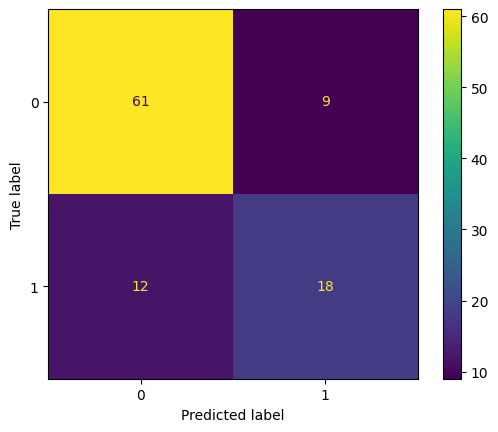

In [24]:
# XGBDT
print("XGBDT Confusion Matrix")
predict = XGB_model.predict(X_test)
print(CM.from_predictions(Y_test, predict))

#### Shifting the Decision Threshold for XGBDT
Changing the decision threshold to improve detection of False Negatives (bad credit clients approved) and False Positives (good credit clients rejected).

XGBDT Confusion Matrix with Custom Threshold = 0.3


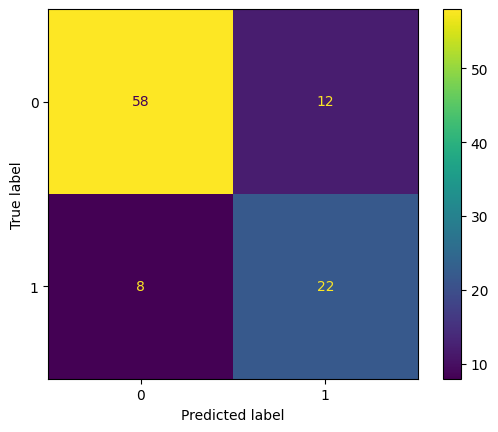

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Get predicted probabilities for Class 1 (bad credit)
# predict_proba returns [prob_class_0, prob_class_1]
y_probabilities = XGB_model.predict_proba(X_test)[:, 1]

# 2. Define a more conservative threshold (e.g., 0.3 instead of 0.5)
custom_threshold = 0.3
custom_predictions = (y_probabilities >= custom_threshold).astype(int)

# 3. Compute and display the new confusion matrix
cm_custom = confusion_matrix(Y_test, custom_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_custom, display_labels=XGB_model.classes_)

print(f"XGBDT Confusion Matrix with Custom Threshold = {custom_threshold}")
disp.plot(cmap='viridis')
plt.show()

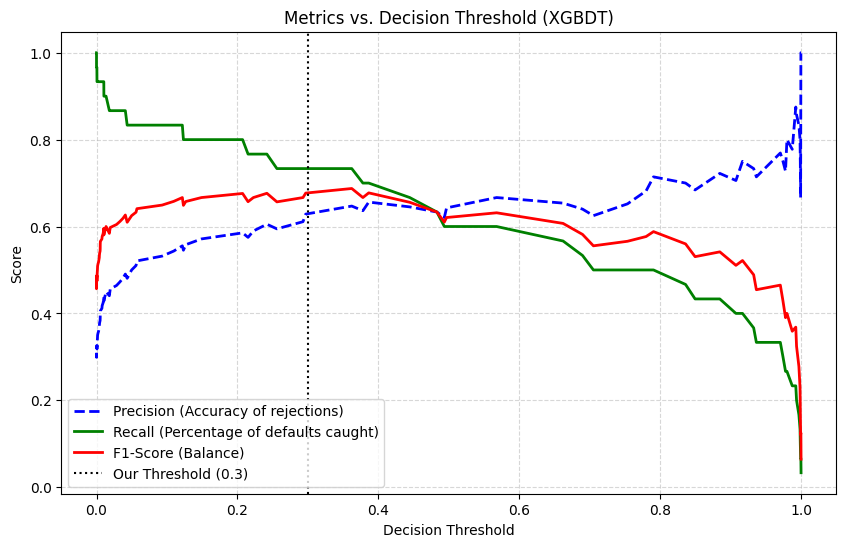

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

y_probabilities = XGB_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(Y_test, y_probabilities)

# Calculate F1-scores for each threshold
# We avoid division by zero using np.where
f1_scores = np.where((precisions + recalls) > 0, (2 * precisions * recalls) / (precisions + recalls), 0)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision (Accuracy of rejections)', lw=2)
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall (Percentage of defaults caught)', lw=2)
plt.plot(thresholds, f1_scores[:-1], 'r-', label='F1-Score (Balance)', lw=2)

# Draw a vertical line highlighting your custom 0.3 threshold
plt.axvline(x=0.3, color='black', linestyle=':', label='Our Threshold (0.3)')

plt.title('Metrics vs. Decision Threshold (XGBDT)')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Why a 0.3 threshold? Because `defaults` (**False Negatives**) are more expensive, it is necessary to sacrifice `some precision` (which we get at a 50% threshold instead, which is the most mathematically balanced option) to force higher `recall`.

**Lowering the threshold to 0.3 acts as an insurance policy for the lending business**.